In [30]:
import numpy as np
import matplotlib.pyplot as plt

La primera ley de Fick es
$$ J=-D\frac{\partial C}{\partial x}$$

$D$ es un parametro que determina la rapidez con la que el $CO_2$ se difunde en el líquido.

- $L$: espesor del líquido (mm)
- $\Delta t$: paso temporal (s)
- $\Delta x$: distancia espacil $(\mu m)$
- `t_final`: tiempo simulado (s)
- $k$: constante de consumo superficial (m/s)

$$r = D \frac{\Delta t}{(\Delta x)^2}$$

In [31]:


L = 1e-3
D = 1.9e-9
k = 1e-4
C_bulk = 33.0  # Concentración exterior

N = 50  # Número de intervalos
dx = L / N

dt = 0.1
t_final = 10
n_steps = int(t_final / dt)

r = D * dt / dx**2

print(f"dx = {dx:.3e} m")
print(f"r = {r:.4f}")

dx = 2.000e-05 m
r = 0.4750


Suponemos que la cantidad de $CO_2$ que consume el electrodo por unidad de área y por unididad de tiempo es igual ala concentración de $CO_2$ justo en la superficie $(C_s)$ del electrodo multiplicada por un factor de proporcionalidad $k$ que dice qué tan ráido consume el electrodo el $CO_2$ disponible.

$$ J_{consumo} = kC_s $$

---

Como tenemos concentraciones en dos posiciones, podemos aproximar la derivada

$$\frac{\partial C}{\partial x}\approx \frac{C_1-C_0}{\Delta x}$$

Y al sustituir la primera ley de Fick $(J=-D\partial C/\partial x)$ queda

$$ J\approx -D\frac{C_1-C_0}{\Delta x}$$

---

Suponemos que no hay acomulción de $CO_2$ en la superficie, entonces el fllujo que llega por difusión debe ser igual al consumo:

$$ J_{dif}=J_{consumo} $$

Sustituyendo

$$D\frac{C_1-C_0}{\Delta x}=kC_0$$

De aquí podemos despejar $C_0$

$$ C_0 = \frac{D}{D+k\Delta x}C_1$$

In [32]:
x = np.linspace(0, L, N + 1)
t = np.arange(n_steps + 1) * dt

C = np.full(N + 1, C_bulk)

alpha = D / (D + k * dx)

C[0] = alpha * C[1]
C[-1] = C_bulk

$C$ contiene la concentración en todos los puntos en un instante. a medida que avanza el tiempo las concentraciones cambian, entonces necesitamos guardar una copia de $C$ en cada instante.

Creamos una matriz de ceros con dimension (número de instantes temporales que vamos a guardar INCLUIDO EL INICIAL)$\times$ (número de puntos iniciales donde calculamos la concentración)

El `C.copy` va guardando el perfil de concentración en la fila $n$ de la matriz

In [33]:
C_history = np.zeros((n_steps + 1, N + 1))
C_history[0] = C.copy()

La segunda ley de Fick es
$$ \frac{\partial C}{\partial t}=D\frac{\partial^2 C}{\partial x^2}$$

Con un desarrollo que esta en el notion llegamos a 

$$C_i^{n+1}=C_i^{n}+r(C_{i+1}^n-2C_i^n+C_{i-1}^n)$$

- `C[1:N]` es la concentración actual $(C_i^n)$
- `C[2:N+1]` es la concentración del vecino a la derecha $(C_{i+1}^n)$
- `C[0:N-1]` concentración del vecino izquierdo $(C_{i-1}^n)$
- `r` es $D\, \Delta t / (\Delta x)^2$
- `C_new[1:N]` es la concentración en el instante siguiente $(C_i^{n+1})$ 

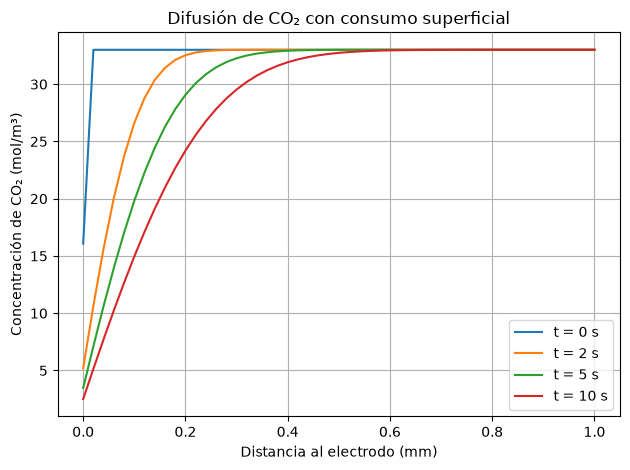

In [34]:
for n in range(n_steps):

    C_new = C.copy()

    C_new[1:N] = C[1:N] + r * (
        C[2:N+1] - 2*C[1:N] + C[0:N-1]
    )

    C_new[0] = alpha * C_new[1]

    C_new[-1] = C_bulk

    # avanzar al siguiente instante
    C = C_new
    C_history[n + 1] = C.copy()

# 7. Graficar perfiles de concentración
for tiempo in [0, 2, 5, 10]:
    indice = int(tiempo / dt)
    plt.plot(
        x * 1e3,
        C_history[indice],
        label=f"t = {tiempo} s"
    )

plt.xlabel("Distancia al electrodo (mm)")
plt.ylabel("Concentración de CO₂ (mol/m³)")
plt.title("Difusión de CO₂ con consumo superficial")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

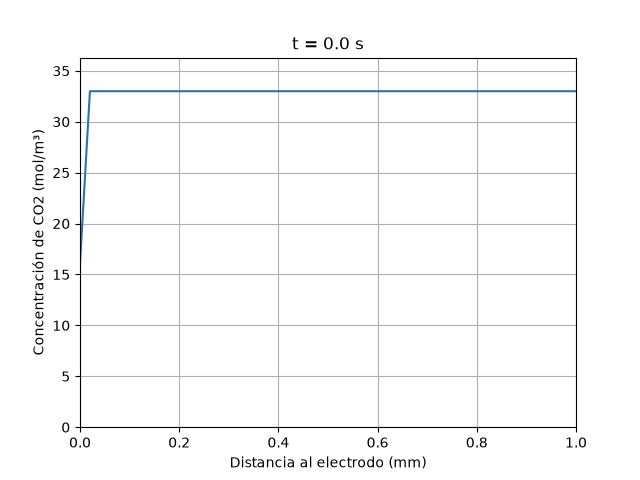

In [35]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

fig, ax = plt.subplots()

line, = ax.plot(x * 1e3, C_history[0])

ax.set_xlim(0, L * 1e3)
ax.set_ylim(0, C_bulk * 1.1)
ax.set_xlabel("Distancia al electrodo (mm)")
ax.set_ylabel("Concentración de CO2 (mol/m³)")
ax.grid()

title = ax.set_title("t = 0 s")

def update(n):
    line.set_ydata(C_history[n])
    title.set_text(f"t = {t[n]:.1f} s")
    return line, title

ani = FuncAnimation(
    fig, update,
    frames=len(t),
    interval=100
)

ani.save("difusion.gif", writer=PillowWriter(fps=10))
plt.close()

display(Image(filename="difusion.gif"))

Suponemos que el volumen de la mezcla no cambia significativamente

$$ \rho(C)= \rho_{bulk}+\beta(C-C_{bulk}) $$

$\beta$ mide cuánto cambia la densidad cuando cambia la concentración.

---

Tenemos la siguiente relación

$$ D(\rho)=D_0\bigg(\frac{\rho_{bulk}}{\rho}\bigg)^m $$

- $D_0$: difusividad de referencia
- $\rho_{bulk}$: densidad de referencia
- $m$: sensibilidad de $D_0$ respecto a $\rho$.

Numero de Fourier: 0.02375
Condicion de estabilidad difusiva: True


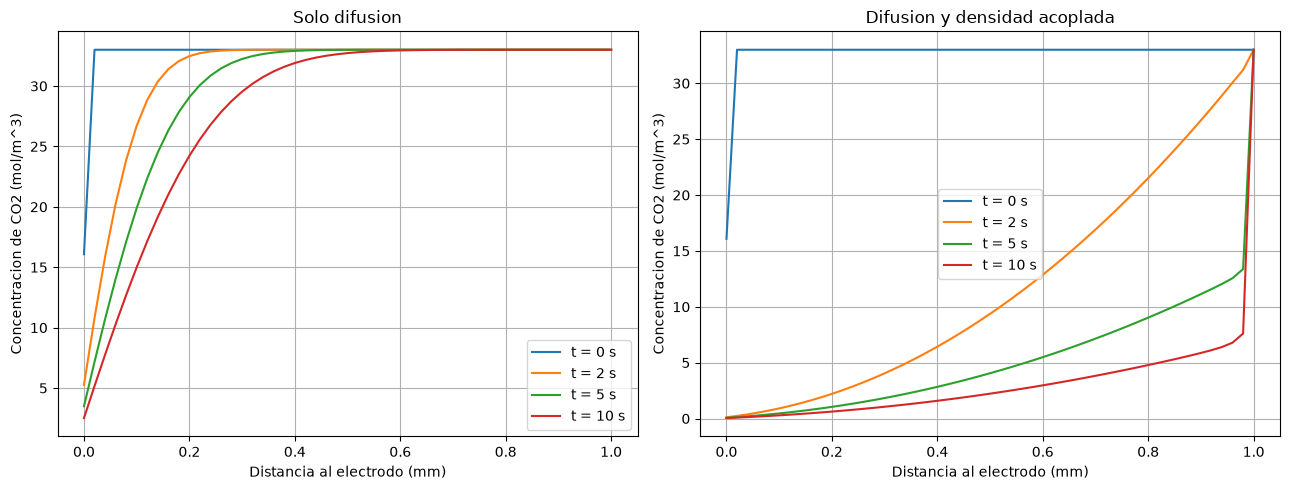

In [40]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

# ============================================================
# 1. PARAMETROS DEL SISTEMA
# ============================================================

L = 1e-3              # Distancia al electrodo (m)
D = 1.9e-9             # Coeficiente de difusion (m^2/s)
k = 1e-4               # Constante de consumo en el electrodo (m/s)
C_bulk = 33.0           # Concentracion de referencia (mol/m^3)

rho_bulk = 1000.0       # Densidad de referencia (kg/m^3)
beta = 0.044             # Acoplamiento concentracion-densidad (kg/mol)

mobility = 1e-7         # Movilidad efectiva (m^4/(kg*s))

N = 50
dx = L / N

dt = 0.005
t_final = 10.0
n_steps = int(t_final / dt)

x = np.linspace(0, L, N + 1)
t = np.arange(n_steps + 1) * dt

# Condicion de frontera en el electrodo
alpha = D / (D + k * dx)

# Numero de Fourier
r = D * dt / dx**2

print("Numero de Fourier:", r)
print("Condicion de estabilidad difusiva:", r <= 0.5)


# ============================================================
# 2. MODELO A: SOLO DIFUSION
# ============================================================

C_diff = np.full(N + 1, C_bulk)
C_diff[0] = alpha * C_diff[1]

C_history_diff = np.zeros((n_steps + 1, N + 1))
C_history_diff[0] = C_diff.copy()

for n in range(n_steps):

    C_new = C_diff.copy()

    # Difusion en los nodos interiores
    C_new[1:N] = C_diff[1:N] + r * (
        C_diff[2:N+1]
        - 2 * C_diff[1:N]
        + C_diff[0:N-1]
    )

    # Frontera del electrodo
    C_new[0] = alpha * C_new[1]

    # Concentracion fijada en el extremo exterior
    C_new[-1] = C_bulk

    C_diff = C_new
    C_history_diff[n + 1] = C_diff.copy()


# ============================================================
# 3. MODELO B: DIFUSION + DENSIDAD + TRANSPORTE EFECTIVO
# ============================================================

C = np.full(N + 1, C_bulk)
C[0] = alpha * C[1]

C_history = np.zeros((n_steps + 1, N + 1))
rho_history = np.zeros((n_steps + 1, N + 1))
u_history = np.zeros((n_steps + 1, N + 1))

C_history[0] = C.copy()

# La densidad depende de la concentracion
rho = rho_bulk - beta * (C - C_bulk)
rho_history[0] = rho.copy()

for n in range(n_steps):

    # --------------------------------------------------------
    # A. Densidad local
    # --------------------------------------------------------

    rho = rho_bulk - beta * (C - C_bulk)

    # --------------------------------------------------------
    # B. Velocidad efectiva a partir del gradiente de densidad
    # --------------------------------------------------------

    drho_dx = np.gradient(rho, dx)
    u = -mobility * drho_dx

    u_history[n] = u.copy()

    # --------------------------------------------------------
    # C. Derivadas espaciales de la concentracion
    # --------------------------------------------------------

    laplacian = (
        C[2:N+1]
        - 2 * C[1:N]
        + C[0:N-1]
    ) / dx**2

    dC_dx = np.zeros(N - 1)

    # Aproximacion upwind para el transporte.
    # Si u > 0, usamos la diferencia hacia atras.
    # Si u < 0, usamos la diferencia hacia adelante.

    for j in range(1, N):

        if u[j] >= 0:
            dC_dx[j - 1] = (C[j] - C[j - 1]) / dx
        else:
            dC_dx[j - 1] = (C[j + 1] - C[j]) / dx

    # --------------------------------------------------------
    # D. Actualizacion de la concentracion
    # --------------------------------------------------------

    C_new = C.copy()

    C_new[1:N] = C[1:N] + dt * (
        D * laplacian
        - u[1:N] * dC_dx
    )

    # Condiciones de frontera
    C_new[0] = alpha * C_new[1]
    C_new[-1] = C_bulk

    C = C_new

    # Guardar los resultados
    C_history[n + 1] = C.copy()

    rho = rho_bulk - beta * (C - C_bulk)
    rho_history[n + 1] = rho.copy()

# Guardar tambien la velocidad del ultimo instante
drho_dx = np.gradient(rho, dx)
u_history[-1] = -mobility * drho_dx


# ============================================================
# 4. COMPARACION DE LOS PERFILES DE CONCENTRACION
# ============================================================

tiempos = [0, 2, 5, 10]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for tiempo in tiempos:

    n = int(tiempo / dt)

    axes[0].plot(
        x * 1e3,
        C_history_diff[n],
        label=f"t = {tiempo} s"
    )

    axes[1].plot(
        x * 1e3,
        C_history[n],
        label=f"t = {tiempo} s"
    )

axes[0].set_title("Solo difusion")
axes[1].set_title("Difusion y densidad acoplada")

for ax in axes:
    ax.set_xlabel("Distancia al electrodo (mm)")
    ax.set_ylabel("Concentracion de CO2 (mol/m^3)")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()



GIF guardado en: difusion_densidad_acoplada.gif


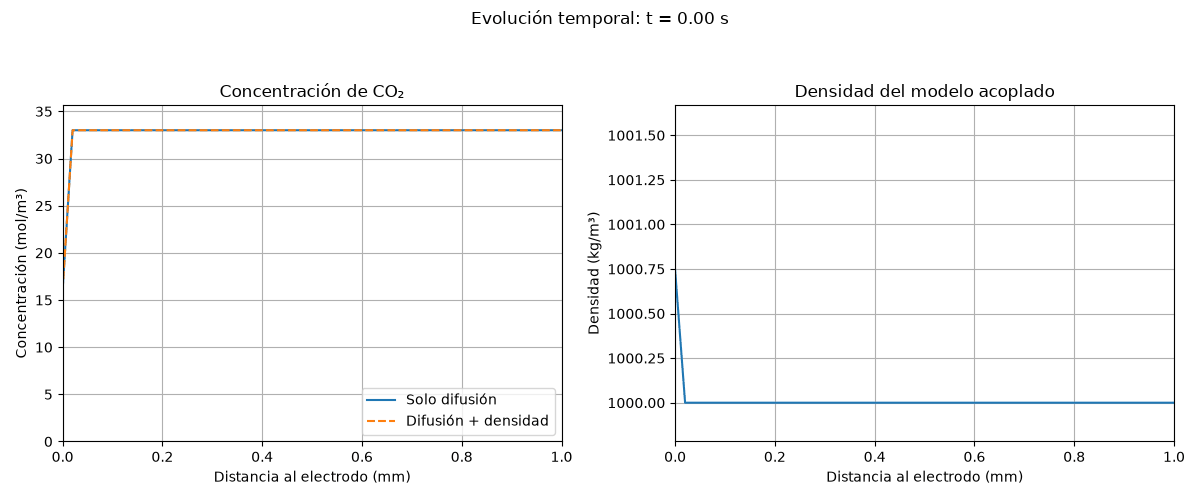

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, Image

# Parameters from the previously proposed model
L = 1e-3
D = 1.9e-9
k = 1e-4
C_bulk = 33.0
rho_bulk = 1000.0
beta = 0.044
mobility = 1e-7

N = 50
dx = L / N
dt = 0.005
t_final = 10.0
n_steps = int(t_final / dt)

x = np.linspace(0, L, N + 1)
t = np.arange(n_steps + 1) * dt
alpha = D / (D + k * dx)

# Diffusion-only reference model
C_diff = np.full(N + 1, C_bulk)
C_diff[0] = alpha * C_diff[1]
C_history_diff = np.zeros((n_steps + 1, N + 1))
C_history_diff[0] = C_diff.copy()

for n in range(n_steps):
    C_new = C_diff.copy()
    C_new[1:N] = C_diff[1:N] + (D * dt / dx**2) * (
        C_diff[2:N+1] - 2*C_diff[1:N] + C_diff[0:N-1]
    )
    C_new[0] = alpha * C_new[1]
    C_new[-1] = C_bulk
    C_diff = C_new
    C_history_diff[n + 1] = C_diff.copy()

# Coupled concentration-density model
C = np.full(N + 1, C_bulk)
C[0] = alpha * C[1]
C_history = np.zeros((n_steps + 1, N + 1))
rho_history = np.zeros((n_steps + 1, N + 1))
u_history = np.zeros((n_steps + 1, N + 1))
C_history[0] = C.copy()
rho_history[0] = rho_bulk - beta * (C - C_bulk)

for n in range(n_steps):
    rho = rho_bulk - beta * (C - C_bulk)
    drho_dx = np.gradient(rho, dx)
    u = -mobility * drho_dx
    u_history[n] = u.copy()

    laplacian = (C[2:N+1] - 2*C[1:N] + C[0:N-1]) / dx**2
    dC_dx = np.zeros(N - 1)

    for j in range(1, N):
        if u[j] >= 0:
            dC_dx[j - 1] = (C[j] - C[j - 1]) / dx
        else:
            dC_dx[j - 1] = (C[j + 1] - C[j]) / dx

    C_new = C.copy()
    C_new[1:N] = C[1:N] + dt * (D * laplacian - u[1:N] * dC_dx)
    C_new[0] = alpha * C_new[1]
    C_new[-1] = C_bulk
    C = C_new

    C_history[n + 1] = C.copy()
    rho_history[n + 1] = rho_bulk - beta * (C - C_bulk)

rho_min = float(np.min(rho_history))
rho_max = float(np.max(rho_history))
rho_pad = max((rho_max - rho_min) * 0.15, 0.002)

# Animate comparison of concentration and coupled density
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=100)

line_diff, = axes[0].plot(x * 1e3, C_history_diff[0], label="Solo difusión")
line_coupled, = axes[0].plot(x * 1e3, C_history[0], "--", label="Difusión + densidad")
axes[0].set_title("Concentración de CO₂")
axes[0].set_xlabel("Distancia al electrodo (mm)")
axes[0].set_ylabel("Concentración (mol/m³)")
axes[0].set_xlim(0, L * 1e3)
axes[0].set_ylim(0, C_bulk * 1.08)
axes[0].grid(True)
axes[0].legend(loc="lower right")

line_rho, = axes[1].plot(x * 1e3, rho_history[0])
axes[1].set_title("Densidad del modelo acoplado")
axes[1].set_xlabel("Distancia al electrodo (mm)")
axes[1].set_ylabel("Densidad (kg/m³)")
axes[1].set_xlim(0, L * 1e3)
axes[1].set_ylim(rho_min - rho_pad, rho_max + rho_pad)
axes[1].grid(True)

time_label = fig.suptitle("Evolución temporal: t = 0.00 s")
fig.tight_layout(rect=[0, 0, 1, 0.93])

# Save fewer frames to keep the GIF reasonably small
frame_indices = np.arange(0, n_steps + 1, 10)
if frame_indices[-1] != n_steps:
    frame_indices = np.append(frame_indices, n_steps)

def update(frame_number):
    n = int(frame_indices[frame_number])
    line_diff.set_ydata(C_history_diff[n])
    line_coupled.set_ydata(C_history[n])
    line_rho.set_ydata(rho_history[n])
    time_label.set_text(f"Evolución temporal: t = {t[n]:.2f} s")
    return line_diff, line_coupled, line_rho, time_label

ani = FuncAnimation(
    fig,
    update,
    frames=len(frame_indices),
    interval=50,
    blit=False
)

# Guardar el GIF en la carpeta actual del proyecto
gif_path = "difusion_densidad_acoplada.gif"

ani.save(gif_path, writer=PillowWriter(fps=20))
plt.close(fig)

print(f"GIF guardado en: {gif_path}")

display(Image(filename=gif_path))